# FashionRAG 웹 앱 만들기 — Streamlit + LangChain 멀티모달 RAG


## 학습 목표
1. Streamlit 은 버튼을 누를 때마다 **파일을 처음부터 다시 읽습니다.(rerun)**. 
2. **주방(로직)과 홀(화면)을 나눠서** 앱을 설계할 수 있습니다.
3. 노트북에서 만든 FashionRAG 를 **웹사이트** 버전으로 구현
4. 노트북과 터미널에서 Streamlit 앱을 동작시킬 수 있습니다.

## 차례
| 파트 | 내용 |
|---|---|
| 0 | 전체 흐름: 노트북 → 주방 파일 → 웹 앱 |
| 1 | 주방 파일 `fashion_rag_core.py` 만들고 노트북에서 실행해 보기 |
| 2 | Streamlit 4가지 (다시 읽기 · 사물함 · 냉장고 · 편지 봉투) + 미니 앱 체험 |
| 3 | FashionRAG 앱 `app.py` 만들고 동작시키기 |
| 4 | 직접 해 보기 · 퀴즈 · 정리 |

---
# Part 0. 전체 흐름 이해하기

지난 시간에는 **노트북 칸**으로 FashionRAG 를 만들었어요. 오늘은 같은 기능을 **누구나 브라우저로 쓸 수 있는 웹사이트(웹 앱)** 로 바꿔봅니다.

### 왜 노트북 칸에서 바로 앱을 못 켤까요?
Streamlit 앱은 `streamlit run 파일.py` 명령으로 여는 **따로 떨어진 가게(웹 서버)** 예요. 그래서 앱 코드는 꼭 **.py 파일**로 있어야 합니다.
그래서 노트북에서는 `%%writefile` 이라는 주문으로 셀 내용을 파일로 저장하고, 도우미 함수로 가게를 열어볼꺼에요.

### 우리 식당(앱)의 구조
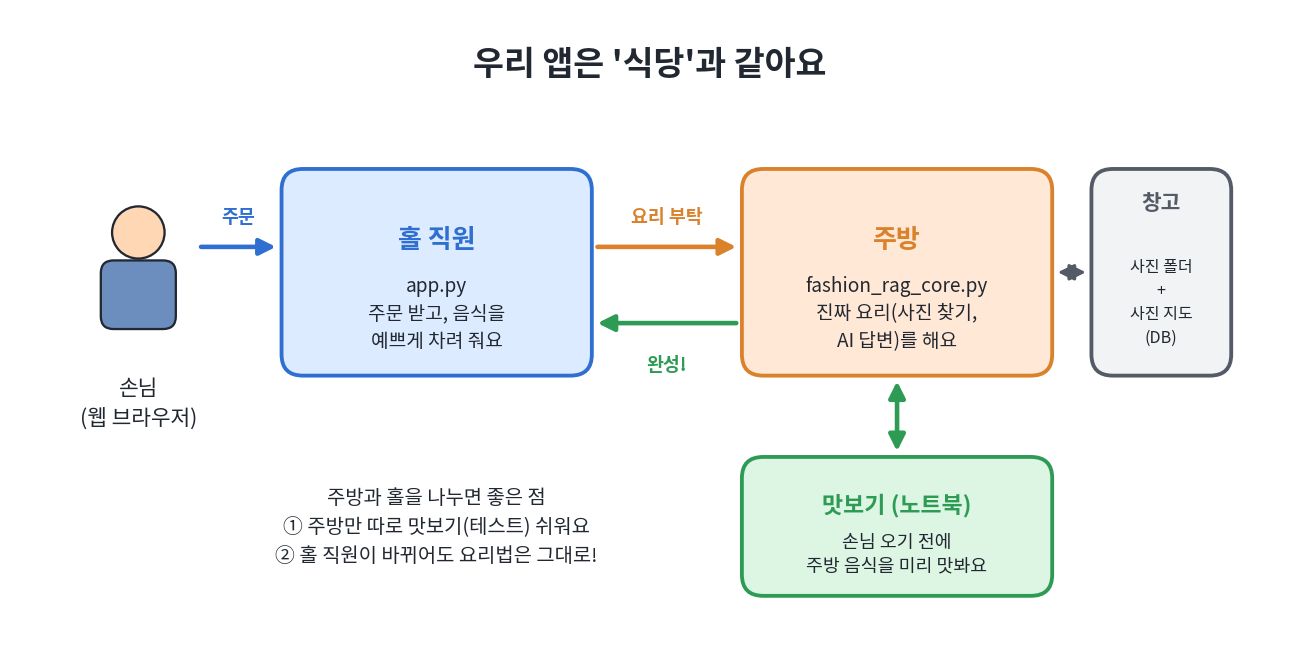

| 식당 | 우리 앱 | 하는 일 |
|---|---|---|
| 손님 | 웹 브라우저 | 질문을 해요 |
| 홀 직원 | `app.py` | 주문 받고, 결과를 화면에 예쁘게 보여 줘요 |
| 주방 | `fashion_rag_core.py` | 사진 찾기·AI 답변 같은 진짜 요리를 해요 |
| 맛보기 | 이 노트북 | 손님이 오기 전에 주방 요리를 미리 맛봐요(테스트) |
| 창고 | `fashion_dataset/`, `img_vdb/` | 사진과 사진 지도(DB)를 보관해요 |

### 폴더 안에는 이런 파일이 생깁니다.
```
작업 폴더/
├── .env                    ← 비밀 열쇠 (OPENAI_API_KEY)
├── 이 노트북.ipynb          ← 맛보기 장소
├── fashion_rag_core.py     ← [Part 1] 주방: 사진·창고·AI 연결
├── hello_app.py            ← [Part 2] Streamlit 원리 체험용 미니 앱
├── app.py                  ← [Part 3] FashionRAG 웹 앱 (홀 직원)
├── app_practice.py         ← [Part 4] 실습 앱
├── fashion_dataset/        ← 사진 폴더 (저절로 생겨요)
└── img_vdb/                ← 사진 창고 DB (저절로 생겨요)
```

### 주방과 홀을 나누면 좋은 점
- **맛보기가 쉬워요**: 화면 없이도 노트북에서 주방 함수만 바로 실행해 볼 수 있습니다.
- **다시 쓸 수 있어요**: 나중에 홀 직원(화면)을 Gradio, FastAPI 같은 다른 것으로 바꿔도 요리법(주방)은 그대로 사용할 수 있습니다.

---
# Part 1. 주방 파일(백엔드 모듈) 만들기

In [ ]:
# ============================================================
# [환경 준비] 필요한 도구(패키지) 설치하기 - 맨 처음 한 번만!
# ============================================================
# 요리를 하려면 먼저 냄비와 재료를 사 와야 하죠? 이 칸이 바로 '장보기'예요.
#   streamlit  : 파이썬만으로 웹사이트 화면을 만들어 주는 도구 (오늘의 주인공!)
#   ipywidgets : 노트북에서 '진행 막대'를 예쁘게 보여 주는 도구 (빨간 경고 글씨도 막아 줘요)
#   나머지     : 지난 시간에 쓴 도구들
#                - open-clip-torch : 사진과 글을 이해하는 AI (CLIP)
#                - chromadb        : 사진을 정리해 두는 창고 (벡터 DB)
#                - langchain-...   : ChatGPT 같은 AI 와 대화하게 연결해 주는 도구
#                - datasets        : 인터넷에서 패션 사진 묶음을 가져오는 도구
#                - python-dotenv   : 비밀 열쇠(API 키)가 적힌 .env 파일을 읽는 도구
# 설치가 끝나고 "Restart Kernel(커널 다시 시작)" 안내가 나오면,
# 게임을 껐다 켜듯 커널을 다시 시작한 뒤 다음 칸부터 실행해 주세요!!

%pip install -q streamlit ipywidgets chromadb open-clip-torch pillow datasets langchain-core langchain-openai python-dotenv

In [1]:
# ============================================================
# [1] 노트북 기본 설정 - "나는 지금 어느 방에 있지?" 확인하기
# ============================================================
import os, sys, importlib   # os: 폴더·파일 다루기 / sys: 파이썬 자체 정보 / importlib: 파일 다시 불러오기

# WORK_DIR = 지금 이 노트북이 들어 있는 폴더(방)의 주소
# sys.path = 파이썬이 "도구 파일이 어디 있지?" 하고 찾아보는 '서랍 목록'
# 우리 폴더를 서랍 목록 맨 앞에 넣어 두면,
# 잠시 뒤 만들 fashion_rag_core.py 를 import(불러오기) 할 때 바로 찾을 수 있습니다.

WORK_DIR = os.getcwd()
if WORK_DIR not in sys.path:          # 서랍 목록에 아직 없을 때만
    sys.path.insert(0, WORK_DIR)      # 맨 앞(0번 자리)에 쏙 끼워 넣기

print("작업 폴더:", WORK_DIR)
print("파이썬 실행 파일:", sys.executable)   # 지금 쓰는 파이썬 프로그램의 위치 (나중에 Streamlit 도 이걸로 켤 거예요)

작업 폴더: c:\Users\user\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-11
파이썬 실행 파일: c:\Users\user\anaconda3\envs\streamlit\python.exe


### `%%writefile` 
칸 맨 첫 줄에 `%%writefile 파일이름` 을 쓰면, **칸 안의 글 전체가 그 이름의 파일로 저장**됩니다.(코드가 실행되지는 않아요!) 같은 이름의 파일이 있으면 새 내용으로 덮어씁니다.

### 콜백(callback) = "중간중간 알려 줘!" 하고 맡기는 연락 방법
`ensure_dataset(progress=...)`, `index_images(progress=...)` 는 일하는 중간에 **우리가 맡긴 함수(연락 방법)** 를 불러서 "지금 몇 개 했어요" 하고 알려 줍니다.
- 노트북에 맡기면: 글자로 `print`
- 웹 앱에 맡기면: 진행 막대(`st.progress`) 채우기

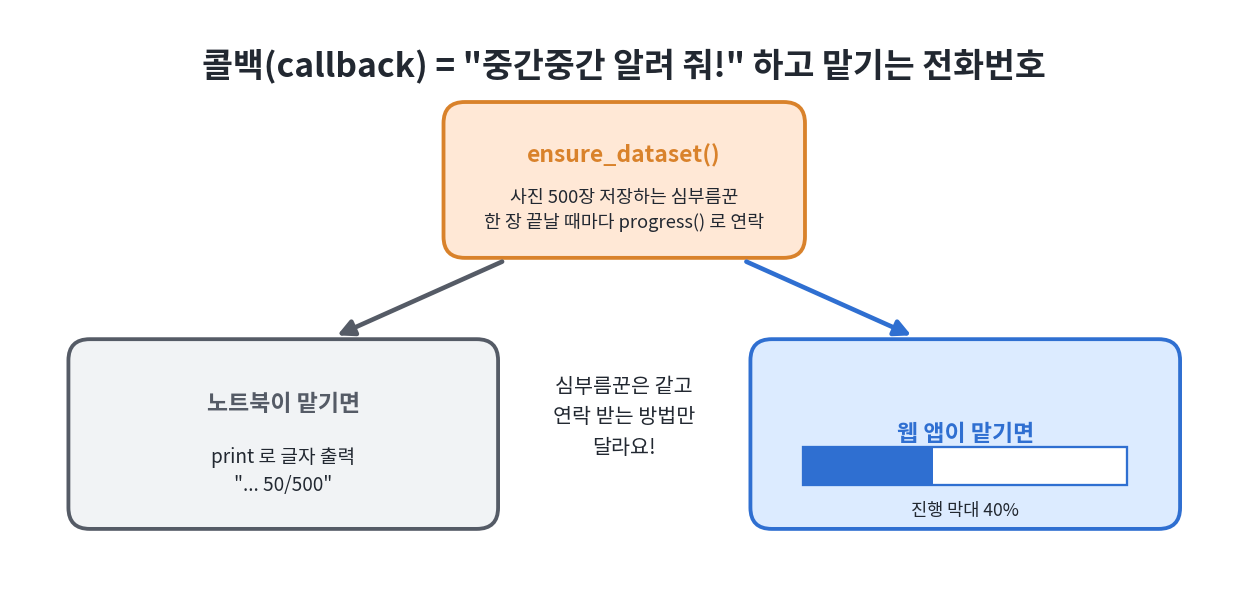

심부름꾼(함수)은 하나인데 **연락받는 방법만 바꿔 끼우니까**, 노트북에서도 앱에서도 똑같은 주방 함수를 쓸 수 있어요.

### 주방에서 하는 요리 미리 보기
아래 파일에서 가장 중요한 함수는 `ask()` 예요. 질문 하나가 이렇게 다섯 단계를 거쳐 답이 됩니다.

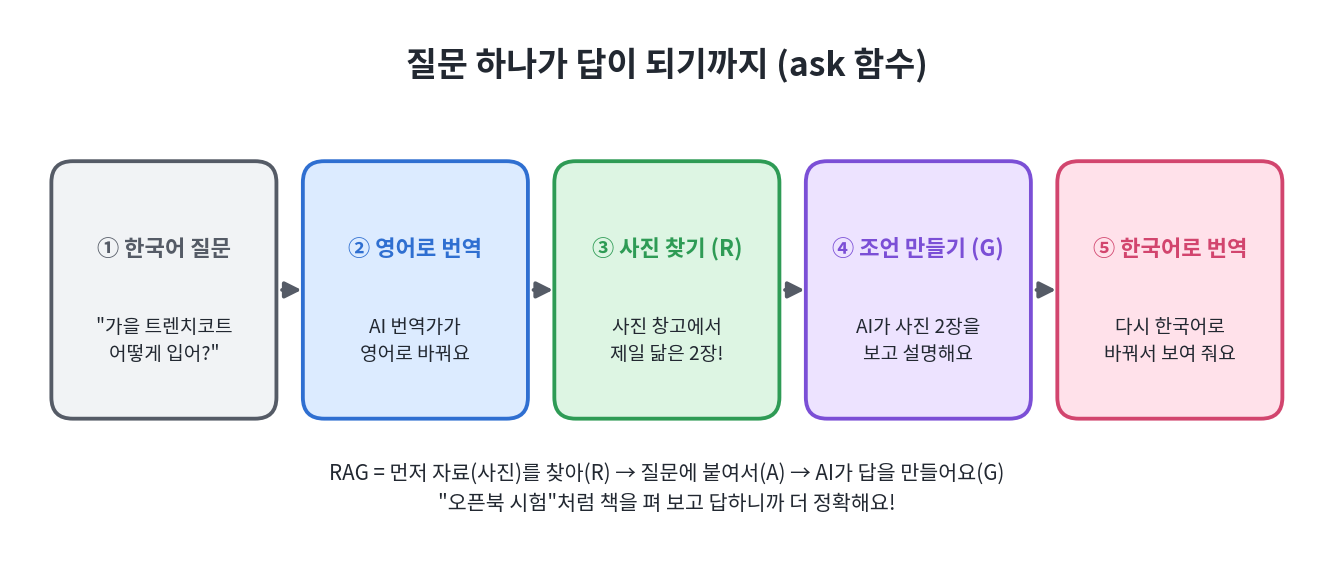

그럼 ③번 "닮은 사진 찾기"는 어떻게 할까요? **CLIP** 이라는 AI 가 글과 사진을 **같은 지도 위의 점**으로 바꿔 줘요. 내 질문 점과 **가까운 점**에 있는 사진이 바로 닮은 사진이에요!

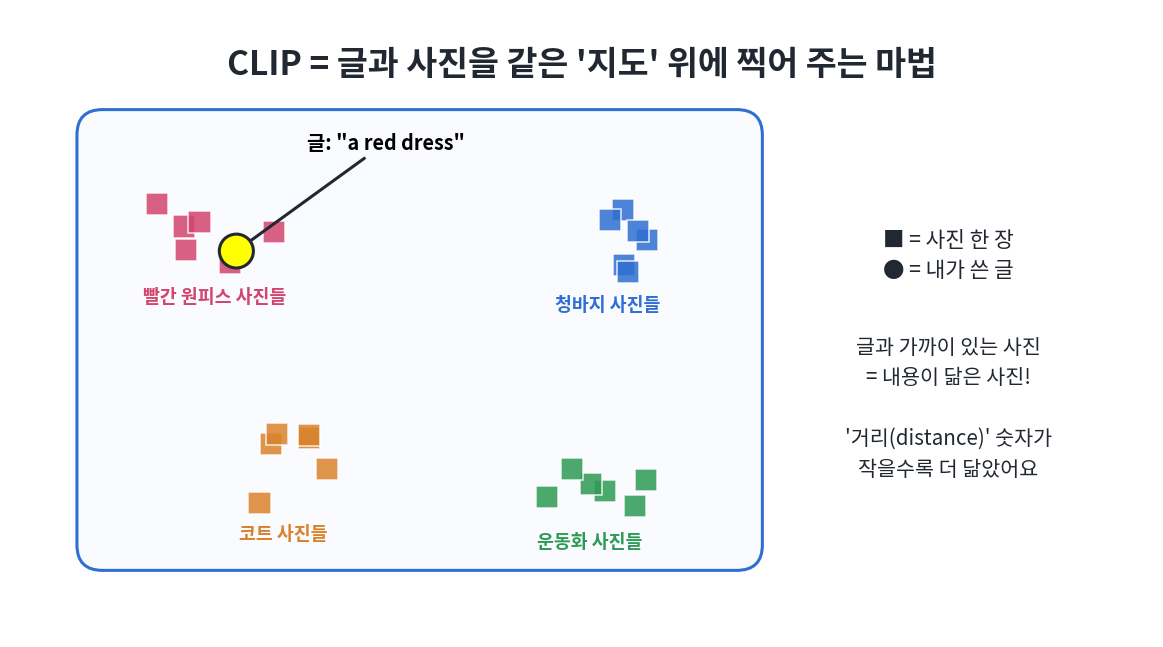

In [2]:
%%writefile fashion_rag_core.py
# ============================================================
# fashion_rag_core.py  -  FashionRAG 의 '주방' (진짜 일을 하는 곳)
# ============================================================
# 식당에 비유하면 이 파일은 '주방'이에요.
#   - 사진 준비하기, 비슷한 사진 찾기, AI 에게 물어보기 같은 '요리'만 해요.
#   - 손님에게 보여 주는 '화면'은 여기서 만들지 않아요. (화면은 app.py = 홀 직원 담당)
# 주방을 따로 두면 좋은 점
#   ① 노트북에서 요리만 따로 맛보기(테스트) 쉬워요.
#   ② 나중에 홀 직원(화면)을 바꿔도 요리법은 그대로 다시 쓸 수 있어요.

import os        # 폴더와 파일을 다루는 도구
import base64    # 사진을 '글자'로 바꾸는 도구

from dotenv import load_dotenv                                        # .env 파일(비밀 열쇠)을 읽는 도구
import chromadb                                                       # 사진 창고(벡터 DB)
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction   # CLIP: 글·사진을 숫자로 바꾸는 AI
from chromadb.utils.data_loaders import ImageLoader                   # 파일 경로를 보고 사진을 열어 주는 도우미
from datasets import load_dataset                                     # 인터넷에서 사진 묶음 가져오기
from langchain_openai import ChatOpenAI                               # ChatGPT 같은 OpenAI 모델과 연결
from langchain_core.prompts import ChatPromptTemplate                 # AI 에게 보낼 '편지 양식'
from langchain_core.output_parsers import StrOutputParser             # AI 답장에서 글자만 쏙 꺼내기

load_dotenv()   # .env 파일 속 비밀 열쇠(OPENAI_API_KEY)를 꺼내서 컴퓨터가 쓸 수 있게 등록해요

# ------------------------------------------------------------
# 설정값 - 요리에 쓰는 '기본 레시피 숫자'들을 한곳에 모아 두기
# ------------------------------------------------------------
# __file__ = "이 파일이 어디에 있는지" 알려 주는 특별한 이름
# (노트북 칸 안에는 없지만, .py 파일 안에서는 쓸 수 있어요)

BASE_DIR        = os.path.dirname(os.path.abspath(__file__))       # 이 파일이 있는 폴더
DATASET_FOLDER  = os.path.join(BASE_DIR, "fashion_dataset")   # 사진을 저장할 폴더
VDB_PATH        = os.path.join(BASE_DIR, "img_vdb")           # 사진 창고(Chroma DB) 폴더
COLLECTION_NAME = "fashion_images"                             # 창고 안 '선반' 이름
NUM_IMAGES      = 500        # 사진 몇 장 쓸까? (원래는 1000장. 시간이 넉넉하면 늘려도 돼요)
N_RESULTS       = 2          # AI 에게 보여 줄 사진 수 (편지 양식에 사진 칸이 2개라서 2장)
TRANSLATION_MODEL = "gpt-4o-mini"   # 번역을 맡을 AI (예전 gpt-3.5-turbo 대신 더 새것)
VISION_MODEL      = "gpt-4o-mini"   # 사진을 보고 설명하는 AI (앱 옆 서랍에서 바꿀 수 있어요)
IMAGE_EXTS = (".jpg", ".jpeg", ".png")   # "이 끝말로 끝나는 파일만 사진으로 칠게요"


def check_api_key():
    """비밀 열쇠(API 키)가 있는지 검사해요. 없으면 ValueError(오류)를 내요.
    파일을 불러오자마자 오류를 내면 앱 화면에 무서운 빨간 글씨가 잔뜩 뜨니까,
    앱에서 이 함수를 불러서 '친절한 안내 문장'으로 보여 주려고 따로 만들었어요."""
    if not os.getenv("OPENAI_API_KEY"):
        raise ValueError("OPENAI_API_KEY 가 없습니다. 노트북과 같은 폴더의 .env 파일에 키를 넣어 주세요.")


# ------------------------------------------------------------
# 파일 도우미 함수들
# ------------------------------------------------------------
def list_image_files(folder=DATASET_FOLDER):
    """폴더 안 사진 파일 이름을 '가나다(번호) 순'으로 줄 세워서 돌려줘요.
    폴더가 아직 없으면 빈 목록 [] 을 돌려줘요."""
    if not os.path.isdir(folder):
        return []
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTS))


def guess_mime(path):
    """파일 끝말(.png / .jpg)을 보고 '이건 어떤 종류의 사진이야'라는 이름표(MIME)를 붙여요.
    AI 에게 사진을 보낼 때 이 이름표가 필요해요."""
    return "image/png" if path.lower().endswith(".png") else "image/jpeg"


def encode_image(path):
    """사진을 base64 '글자'로 바꿔요.
    AI 에게 보내는 편지는 글자만 들어갈 수 있어서, 사진을 글자로 바꿔서 넣어야 해요."""
    with open(path, "rb") as f:                       # rb = 사진을 있는 그대로(바이트로) 읽기
        return base64.b64encode(f.read()).decode("utf-8")


# ------------------------------------------------------------
# 1) 재료 준비 - 패션 사진 모으기
# ------------------------------------------------------------
def ensure_dataset(num_images=NUM_IMAGES, progress=None):
    """사진이 num_images 장보다 적으면 인터넷(Fashionpedia)에서 받아와 저장해요.

    progress : "중간중간 알려 줘!" 하고 맡겨 두는 '연락 함수(콜백)'예요. 모양: (done, total)
               노트북은 print(글자 출력)를, 웹 앱은 진행 막대 함수를 넘겨줘요.
               => 심부름꾼(이 함수)은 같고, 연락받는 방법만 바꿔 끼울 수 있어요!
    """
    os.makedirs(DATASET_FOLDER, exist_ok=True)       # 사진 폴더 만들기 (이미 있으면 그냥 넘어가요)
    if len(list_image_files()) >= num_images:
        return 0                                   # 사진이 이미 충분하면 아무것도 안 하고 끝!


    # 전체(약 3.5GB)를 다 받으면 너무 오래 걸려요.
    # streaming=True = 수도꼭지처럼 '필요한 만큼만' 조금씩 받아 오기

    dataset = load_dataset("detection-datasets/fashionpedia", split="train", streaming=True)
    saved = 0                                        # 지금까지 저장한 사진 수

    for i, example in enumerate(dataset.take(num_images)):   # 앞에서부터 num_images 장만 꺼내기

        # 파일 이름을 image_0001.jpg 처럼 '0을 채운 4자리'로 만들어요.
        # (image_1, image_10, image_2 처럼 순서가 뒤죽박죽 되는 걸 막아 줘요)

        path = os.path.join(DATASET_FOLDER, f"image_{i + 1:04d}.jpg")
        # 사진 색 방식을 RGB 로 통일해서 JPG 로 저장 (투명 배경 사진은 JPG 로 저장이 안 되거든요)

        example["image"].convert("RGB").save(path, format="JPEG", quality=90)
        saved += 1
        if progress:                                 # 연락 함수를 받았다면
            progress(saved, num_images)              # "지금 몇 장 중 몇 장 했어요!" 하고 알려 주기
    return saved


# ------------------------------------------------------------
# 2) 사진 창고(벡터 DB)
# ------------------------------------------------------------
def get_collection():
    """CLIP(글·사진을 숫자 지도로 바꾸는 AI)이 연결된 사진 창고 선반을 돌려줘요.
    CLIP 은 약 600MB 로 아주 무거워요. 그래서 앱에서는 '냉장고(캐시)'에 넣어 딱 한 번만 불러요."""

    client = chromadb.PersistentClient(path=VDB_PATH)      # 창고 열기 (껐다 켜도 내용이 남는 창고)
    return client.get_or_create_collection(               # 선반이 있으면 가져오고, 없으면 새로 만들기
        name=COLLECTION_NAME,
        embedding_function=OpenCLIPEmbeddingFunction(),   # 글이든 사진이든 '같은 지도' 위 좌표(숫자 512개)로 바꿔 줌
        data_loader=ImageLoader(),                        # 파일 주소만 주면 사진을 열어 주는 도우미
    )


def index_images(collection, batch_size=50, progress=None):
    """폴더 사진 중에서 창고에 '아직 없는 사진만' 골라 지도에 점을 찍어(등록해) 둬요.
        collection.get(include=[]) 로 '이름표(id) 목록만' 가볍게 받아 와요.
    """

    files = list_image_files()                                  # 폴더에 있는 사진들
    existing = set(collection.get(include=[])["ids"])           # 창고에 이미 있는 사진 이름표들

    # 이름표(id) = 파일 이름에서 .jpg 를 뗀 것 (예: image_0001)
    # 그래야 "창고의 image_0001 = 폴더의 image_0001.jpg" 로 딱 맞아떨어져요.

    todo = [(os.path.splitext(f)[0], os.path.join(DATASET_FOLDER, f))
            for f in files if os.path.splitext(f)[0] not in existing]   # 창고에 없는 것만 '할 일 목록'에
    for start in range(0, len(todo), batch_size):               # 50장씩 묶어서 차례대로
        batch = todo[start:start + batch_size]
        collection.add(ids=[i for i, _ in batch], uris=[u for _, u in batch])   # 이름표 + 파일 주소로 등록
        if progress:
            progress(min(start + batch_size, len(todo)), len(todo))             # "몇 장 했어요!" 연락
    return len(todo)                                            # 새로 등록한 사진 수


def query_db(collection, query, n_results=N_RESULTS):
    """글(query)과 지도에서 가장 가까운 = 가장 닮은 사진을 n_results 장 찾아요.
    결과는 [[...]] 처럼 상자 안의 상자 모양이에요. (바깥 상자 = 질문, 안쪽 상자 = 1등, 2등...)"""
    return collection.query(query_texts=[query], n_results=n_results,
                            include=["uris", "distances"])     # 사진 주소 + 거리(작을수록 닮음)도 같이 받기


# ------------------------------------------------------------
# 3) AI 연결 줄(체인) 만들기 - LangChain
# ------------------------------------------------------------
def build_chains(translation_model=TRANSLATION_MODEL, vision_model=VISION_MODEL):
    """두 개의 AI 연결 줄을 만들어서 (번역 체인, 비전 체인) 으로 돌려줘요.
    체인 = '편지 양식 | AI | 답장에서 글자만 꺼내기' 를 기차처럼 | 로 이어 붙인 것"""
    #    
    #  {target_lang} 빈칸을 두고, 체인은 한 번만 만들어 계속 써요.

    translation_chain = (
        ChatPromptTemplate.from_messages([
            # system = AI 에게 주는 '역할 카드': "너는 번역가야. {target_lang}(으)로 번역해 줘"
            ("system", "You are a professional translator. Translate the following text to {target_lang}. "
                       "Keep markdown formatting. Output only the translation."),
            ("user", "{text}"),                                  # 번역할 글이 들어갈 빈칸
        ])
        | ChatOpenAI(model=translation_model, temperature=0.0)  # temperature=0 = 매번 똑같이, 차분하게 대답
        | StrOutputParser()                                     # 답장에서 글자만 꺼내기
    )
    
    vision_chain = (
        ChatPromptTemplate.from_messages([
            # 역할 카드: "너는 친절한 패션 도우미야. 사진을 보면서 대화하듯 설명해 줘"
            ("system",
             "You are a helpful fashion and styling assistant. Answer the user's question using the given "
             "image context with direct references to parts of the images provided. Maintain a more "
             "conversational tone, don't make too many lists. Use markdown formatting for highlights, "
             "emphasis, and structure."),
            ("user", [
                {"type": "text", "text": "What are some ideas for styling {user_query}"},   # 질문 빈칸
                # 사진 칸 2개: data:이름표;base64,글자로-바꾼-사진 모양으로 넣어요
                {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
                {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
            ]),
        ])
        | ChatOpenAI(model=vision_model, temperature=0.0)
        | StrOutputParser()
    )
    return translation_chain, vision_chain


def format_prompt_inputs(results, user_query):
    """찾은 사진 중 1등·2등 사진과 질문을 '편지 양식의 빈칸'에 채울 수 있게 사전(dict)으로 만들어요."""
    uris = results["uris"][0]                     # 첫 번째 질문의 결과 사진 주소들
    if len(uris) < 2:   # 사진이 2장보다 적으면, 알아보기 쉬운 말로 오류를 알려 줘요
        raise ValueError(f"이미지가 최소 2장 필요합니다. (검색 결과 {len(uris)}장)")
    inputs = {"user_query": user_query}           # 질문 빈칸 채우기
    for n, path in enumerate(uris[:2], start=1):  # n = 1, 2
        inputs[f"image_data_{n}"] = encode_image(path)   # 사진 → 글자
        inputs[f"image_mime_{n}"] = guess_mime(path)     # 사진 종류 이름표
    return inputs


def ask(collection, chains, query_ko, n_results=N_RESULTS):
    """한국어 질문 하나를 받아서 → 번역 → 사진 찾기 → AI 조언 → 다시 한국어로!
    화면에 보여 줄 것들을 사전(dict) 한 상자에 담아서 돌려줘요."""
    translation_chain, vision_chain = chains
    query_en = translation_chain.invoke({"text": query_ko, "target_lang": "English"})   # ① 영어로 번역
    results = query_db(collection, query_en, n_results)                                # ② 닮은 사진 찾기 (R: 찾기)
    inputs = format_prompt_inputs(results, query_en)                                   # ③ 편지 빈칸 채우기 (A: 붙이기)
    answer_en = vision_chain.invoke(inputs)                                            # ④ AI 가 사진 보고 답 (G: 만들기)
    answer_ko = translation_chain.invoke({"text": answer_en, "target_lang": "Korean"}) # ⑤ 한국어로 번역
    return {
        "query_ko": query_ko, "query_en": query_en,                                     # 질문 (한국어/영어)
        "ids": results["ids"][0], "uris": results["uris"][0], "distances": results["distances"][0],  # 찾은 사진 정보
        "answer_ko": answer_ko,                                                         # 최종 답
    }

Writing fashion_rag_core.py


In [3]:
# ============================================================
# [3] 주방(백엔드 모듈) 불러오기
# ============================================================
import fashion_rag_core as core   # 방금 만든 파일을 'core' 라는 짧은 별명으로 불러와요
importlib.reload(core)            # 파일을 고친 뒤에도 '새 내용'으로 다시 불러오기 (안 하면 옛날 내용이 남아요)

core.check_api_key()              # 비밀 열쇠가 없으면 여기서 친절하게 알려 줘요
print("모듈 위치    :", core.__file__)        # 주방 파일이 어디 있는지
print("이미지 폴더  :", core.DATASET_FOLDER)  # 사진이 저장될 폴더
print("벡터 DB 폴더 :", core.VDB_PATH)        # 사진 창고 폴더

모듈 위치    : c:\Users\user\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-11\fashion_rag_core.py
이미지 폴더  : c:\Users\user\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-11\fashion_dataset
벡터 DB 폴더 : c:\Users\user\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-11\img_vdb


In [4]:
# ============================================================
# [4] 재료 준비 + 창고 정리 (노트북에서 미리 한 번! -> 앱을 처음 켤 때 기다리지 않아요)
# ============================================================
# 연락 함수(콜백): 심부름꾼이 "지금 몇 장 했어요" 하고 알려 줄 때 실행될 함수
# 50장마다 한 번, 그리고 마지막에 한 번만 글자로 보여 줘요.

def print_progress(done, total):
    if done % 50 == 0 or done == total:      # % = 나머지. 50으로 나눠떨어지면 = 50장째, 100장째...
        print(f"  ... {done}/{total}")

print("① 이미지 준비")
n_saved = core.ensure_dataset(progress=print_progress)    # 연락 함수로 print_progress 를 맡겨요
print(f"   새로 저장: {n_saved}장 / 폴더 전체: {len(core.list_image_files())}장")


print("② CLIP 모델 로딩 + 컬렉션 연결 (첫 실행 시 가중치 다운로드)")
collection = core.get_collection()                        # 무거운 CLIP 을 불러오고 창고 선반 열기


print("③ 임베딩 색인")
n_indexed = core.index_images(collection, progress=print_progress)   # 새 사진만 지도에 점 찍기
print(f"   새로 등록: {n_indexed}장 / DB 전체: {collection.count()}장")


① 이미지 준비


  ... 50/500
  ... 100/500
  ... 150/500
  ... 200/500
  ... 250/500
  ... 300/500
  ... 350/500
  ... 400/500
  ... 450/500
  ... 500/500
   새로 저장: 500장 / 폴더 전체: 500장
② CLIP 모델 로딩 + 컬렉션 연결 (첫 실행 시 가중치 다운로드)
③ 임베딩 색인
  ... 50/500
  ... 100/500
  ... 150/500
  ... 200/500
  ... 250/500
  ... 300/500
  ... 350/500
  ... 400/500
  ... 450/500
  ... 500/500
   새로 등록: 500장 / DB 전체: 500장


번역된 질문: Let me know how to style a trench coat that's great for autumn.
  image_0264  distance=0.7141
  image_0019  distance=0.7232


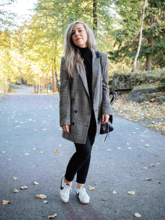

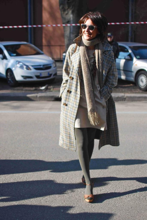

트렌치 코트를 가을에 스타일링하는 것은 재미있고 세련될 수 있습니다! 제공하신 이미지를 바탕으로 몇 가지 아이디어를 소개합니다:

### 1. **터틀넥과 레이어링하기**
첫 번째 이미지에서는 세련된 검은색 터틀넥과 함께 트렌치 코트가 매치되어 있어 세련된 느낌을 더합니다. **중립색 또는 가을 색상의 핏된 터틀넥 위에 트렌치를 레이어링해 보세요.** 이렇게 하면 따뜻함을 유지할 수 있을 뿐만 아니라 매끈한 실루엣을 만들어냅니다.

### 2. **패턴 믹스하기**
두 번째 이미지에서는 체크 패턴의 트렌치 코트가 간단한 드레스와 타이츠와 함께 스타일링되어 있습니다. **패턴 믹스를 두려워하지 마세요!** 트렌치 코트에 대담한 패턴이 있다면, 그 아래 레이어는 간단하게 유지하거나 그 반대로 해보세요. 체크 트렌치 아래에 스트라이프 상의를 매치하면 장난스럽고도 스타일리시한 룩을 연출할 수 있습니다.

### 3. **스카프로 액세서리하기**
두 가지 의상 모두 스카프를 특징으로 하고 있으며, 이는 가을에 완벽합니다. **트렌치와 잘 어울리는 두꺼운 니트 스카프를 선택하세요.** 이렇게 하면 질감과 따뜻함이 더해져 의상이 아늑하고 매력적으로 보입니다.

### 4. **신발 선택**
첫 번째 이미지에서는 흰색 스니커즈가 캐주얼한 느낌을 주고, 두 번째 의상에서는 더 세련된 룩을 위해 힐이 특징입니다. **상황에 맞는 신발을 선택하세요**—편안한 외출에는 스니커즈를, 좀 더 차려입은 모습에는 앵클 부츠를 선택하세요.

### 5. **색상 놀이**
가을은 풍부하고 따뜻한 색상이 특징입니다. **버건디, 머스터드, 올리브 그린과 같은 색상을 의상에 포함하세요.** 예를 들어, 중립색 트렌치 아래에 머스터드 스웨터를 매치하면 아름다운 대비를 만들어낼 수 있습니다.

### 6. **맞춤 핏**
트렌치 코트가 잘 맞는지 확인하세요. 맞춤형 트렌치는 전체적인 룩을 한층 높여주어 더 정돈된 느낌을 줍니다. **허리를 벨트로 조여서 정의감을 더해보세요.**

### 7. **캐주얼 vs. 드레시**
계획에 따라 트렌치 코트를 캐주얼 또는 드레시한 경우에 맞게 스타일링할 수 있습니다. **캐주얼한 룩을 원한다면 청바지와 그래픽 티셔츠와 매치하세요.** 드레시한 느낌을 원한다면 핏된 드레스나 맞춤형 바지를 선택하세요.

이 요소들을 믹스 앤 매치하여 트렌치 코트로 다양한 스타일리시한 가을 룩을 만들어보세요! 실험하는 것을 즐기세요! 🍂✨

In [5]:
# ============================================================
# [5] 주방 맛보기 - 화면 없이 요리(기능)만 먼저 확인해요
# ============================================================

from IPython.display import display, Markdown   # 노트북에 사진·꾸민 글을 보여 주는 도구
from PIL import Image                            # 사진을 열고 크기를 줄이는 도구

chains = core.build_chains()                     # 번역 AI 줄 + 사진 설명 AI 줄 만들기
result = core.ask(collection, chains, "가을에 입기 좋은 트렌치코트 스타일링 알려줘")   # 질문 한 번 해 보기!

print("번역된 질문:", result["query_en"])         # AI 가 영어로 바꾼 질문
for pid, dist in zip(result["ids"], result["distances"]):   # zip = 두 목록을 짝꿍끼리 묶어 꺼내기
    print(f"  {pid}  distance={dist:.4f}")       # 사진 이름표와 거리 (작을수록 질문과 닮았어요)
for uri in result["uris"]:
    im = Image.open(uri); im.thumbnail((220, 220)); display(im)   # 사진을 작게 줄여서 보여 주기
display(Markdown(result["answer_ko"]))           # AI 의 한국어 조언을 예쁘게 보여 주기

---
# Part 2. Streamlit 의 4가지 특징 알기

### Streamlit 이 뭐예요?
HTML·CSS·JavaScript 같은 어려운 웹 언어 없이 **파이썬만으로 웹 화면**을 만드는 도구입니다. `st.title()`, `st.button()` 처럼 함수를 부르면, **부른 순서대로** 화면에 하나씩 그려져요.

### 비밀 ① 버튼을 누르면 처음부터 다시 읽어요 (rerun)
**버튼, 입력 칸, 슬라이더 같은 것(위젯)을 건드릴 때마다 파일 전체를 1줄부터 끝까지 다시 실행**해요.

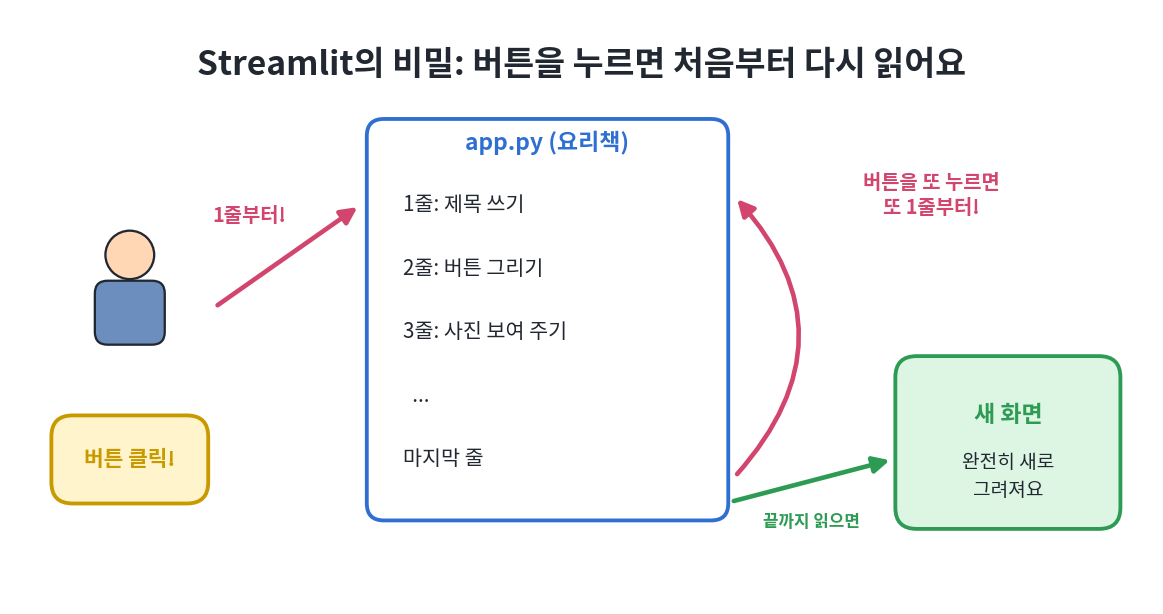

아주 단순해서 배우기 쉽지만, 대신 세 가지 항목에 신경써야 합니다.

| 고민 | 해결 도구 | 쉬운 비유 |
|---|---|---|
| 보통 변수는 다시 읽을 때마다 지워져요 | `st.session_state` | **내 사물함** — 다시 실행돼도 그대로 남아 있어요 (손님마다 따로) |
| 무거운 일을 매번 또 해요 | `@st.cache_resource` | **냉장고** — 모델·DB 연결처럼 무거운 것은 한 번 만들어 넣어 두고 꺼내 써요 (모든 손님이 같이 씀) |
| | `@st.cache_data` | **반찬통** — 표·목록 같은 계산 결과를 재료별로 보관해요 |
| 한 글자 칠 때마다 실행돼요 | `st.form` | **편지 봉투** — 제출 버튼(우체통)을 눌러야 딱 한 번 실행돼요 |

### 비밀 ② 칠판(일반 변수) vs 사물함(session_state)
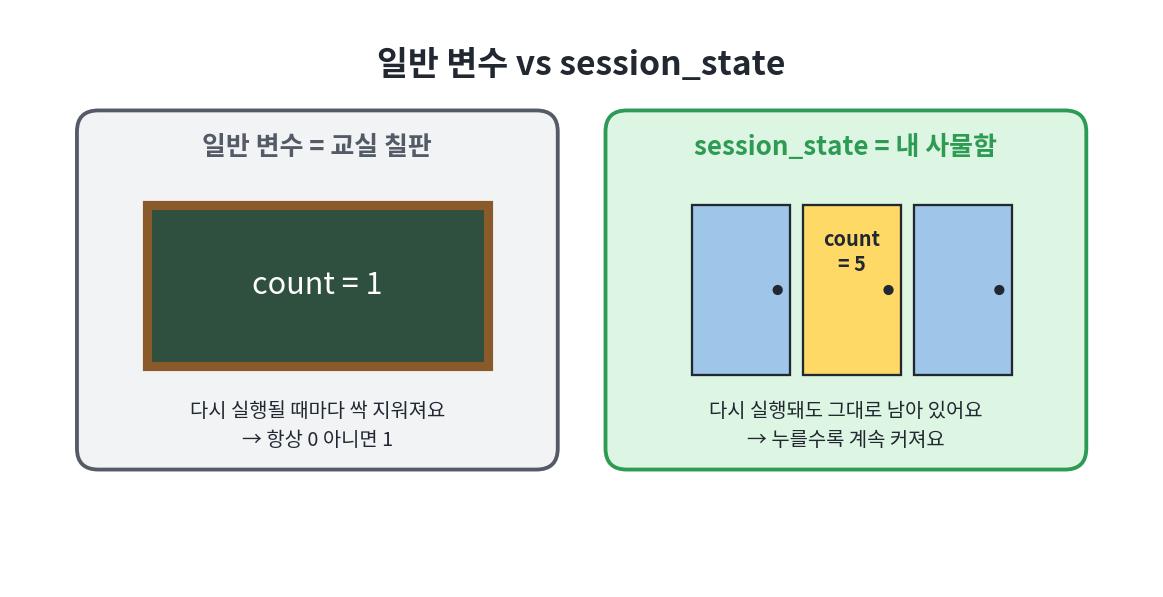

### 비밀 ③ 냉장고(cache_resource)
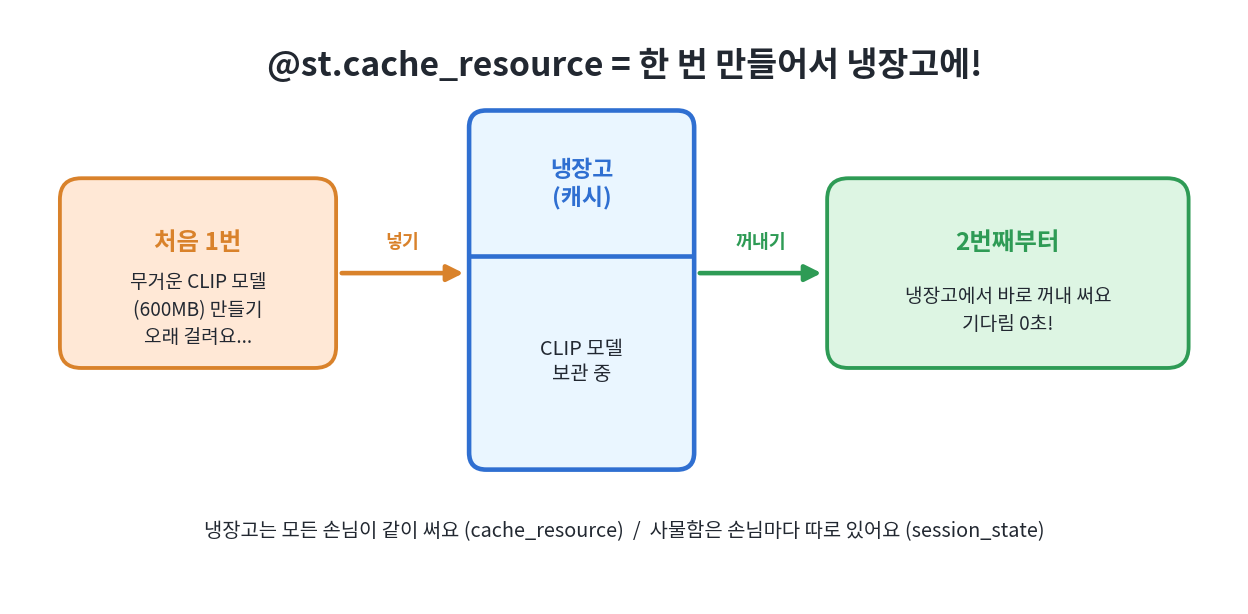

### 비밀 ④ 편지 봉투(form)
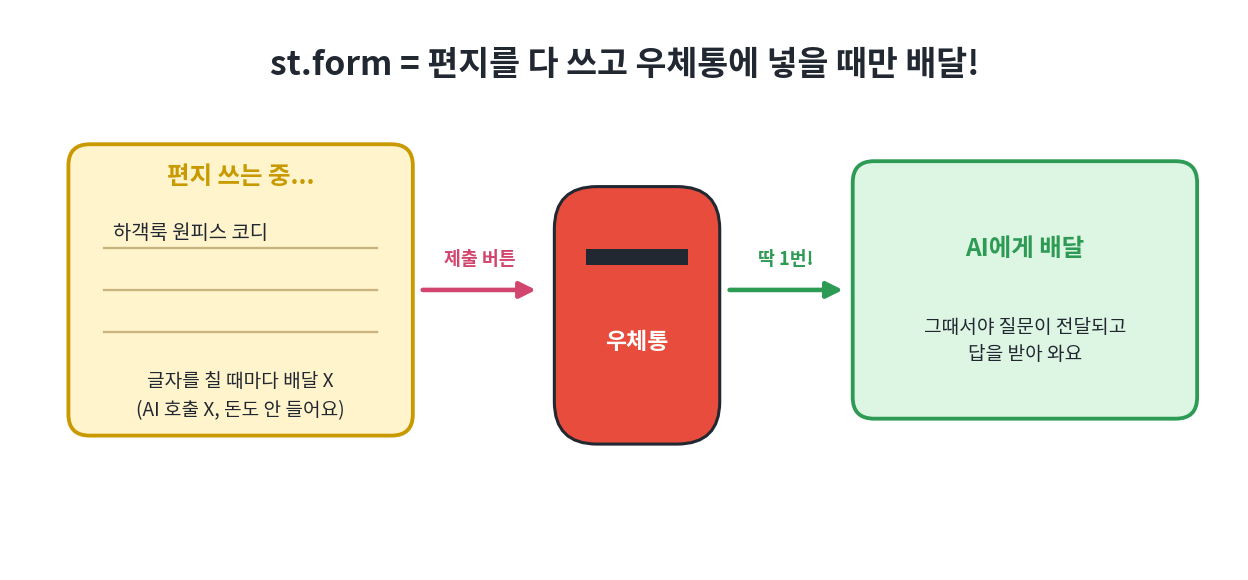

### 자주 쓰는 명령 모음
| 종류 | 명령 | 한마디 설명 |
|---|---|---|
| 페이지 | `st.set_page_config` | 탭 이름·화면 넓이 정하기 (**꼭 제일 먼저!**) |
| 글 | `st.title`, `st.header`, `st.subheader`, `st.write`, `st.markdown`, `st.caption` | 큰 제목 → 작은 글씨까지 |
| 입력 | `st.text_input`, `st.button`, `st.selectbox`, `st.slider`, `st.form` / `st.form_submit_button` | 글 칸, 버튼, 고르기 상자, 미끄럼 막대, 편지 봉투 |
| 배치 | `st.sidebar`, `st.columns`, `st.expander`, `st.divider` | 옆 서랍, 가로로 나란히, 접는 상자, 가로줄 |
| 상태 | `st.spinner`, `st.progress`, `st.status`, `st.info` / `st.success` / `st.error`, `st.stop` | 빙글빙글, 진행 막대, 진행 상자, 파랑/초록/빨강 안내, 멈춤 |
| 사진 | `st.image` | 파일 주소·사진·인터넷 주소 모두 OK |

In [6]:
%%writefile hello_app.py
# ============================================================
# hello_app.py - Streamlit 이 어떻게 움직이는지 체험하는 꼬마 앱
# ============================================================
import time                 # 시계 도구
import streamlit as st      # Streamlit 을 'st' 라는 짧은 별명으로 불러오기

st.title("Streamlit 동작 원리 체험")              # 화면 맨 위에 큰 제목 쓰기

# ── ① 다시 실행(rerun) 확인 ──────────────────────────────────
# 버튼 같은 걸 누를 때마다 이 파일 전체가 '1줄부터 다시' 실행돼요.
# 그래서 버튼을 누를 때마다 아래 시각이 새로 바뀌어요!
st.write("이 스크립트가 실행된 시각:", time.strftime("%H:%M:%S"))

# ── ② 칠판(일반 변수) vs 사물함(session_state) ────────────────
count = 0                                          # 칠판: 다시 실행될 때마다 0 으로 지워져요
if "count" not in st.session_state:                # 사물함에 count 가 아직 없다면 (맨 처음 한 번만)
    st.session_state.count = 0                     #   사물함에 0 을 넣어 두기

if st.button("+1 누르기"):                         # 버튼을 '누른 바로 그 순간'의 실행에서만 True(참)
    count += 1                                     # 칠판 숫자 +1 (다음 실행엔 다시 0)
    st.session_state.count += 1                    # 사물함 숫자 +1 (계속 남아요)

st.write("일반 변수 count =", count)               # 항상 0 아니면 1
st.write("session_state.count =", st.session_state.count)   # 누를수록 1, 2, 3... 계속 커져요

# ── ③ 냉장고(캐시) ────────────────────────────────────────────
@st.cache_resource                                  # "이 함수의 결과는 냉장고에 넣어 두고 다시 꺼내 써!"
def load_heavy_model():
    time.sleep(3)                                   # 무거운 모델을 불러오는 척 3초 기다리기
    return {"name": "가짜 모델", "loaded_at": time.strftime("%H:%M:%S")}

model = load_heavy_model()                          # 처음만 3초, 그다음부터는 냉장고에서 바로 꺼내요
st.write("모델 로딩 시각(캐시라서 바뀌지 않음):", model["loaded_at"])

# ── ④ 편지 봉투(form) ────────────────────────────────────────
# 봉투 안에서 글자를 칠 때는 아무 일도 안 일어나고,
# '제출' 버튼(우체통)을 눌러야 그때 한 번 다시 실행돼요.
with st.form("demo_form"):                          # 여기서부터 봉투 안
    name = st.text_input("이름")                    # 이름 쓰는 칸
    submitted = st.form_submit_button("제출")       # 제출 버튼 (누르면 True)
if submitted:                                       # 제출했을 때만
    st.success(f"안녕하세요, {name}님!")            # 초록색 인사 상자 보여 주기

Writing hello_app.py


### 가게 열기 · 닫기
Streamlit 앱은 **가게(웹 서버)** 처럼 문을 열어야 손님(브라우저)이 들어올 수 있어요. 아래 칸의 `start_app()` 은 문 열기, `stop_app()` 은 문 닫기예요.
**포트(port)** 는 가게 호수(8501호)예요. 같은 호수에는 가게를 두 개 열 수 없으니, 다 쓰면 꼭 닫아 주세요!

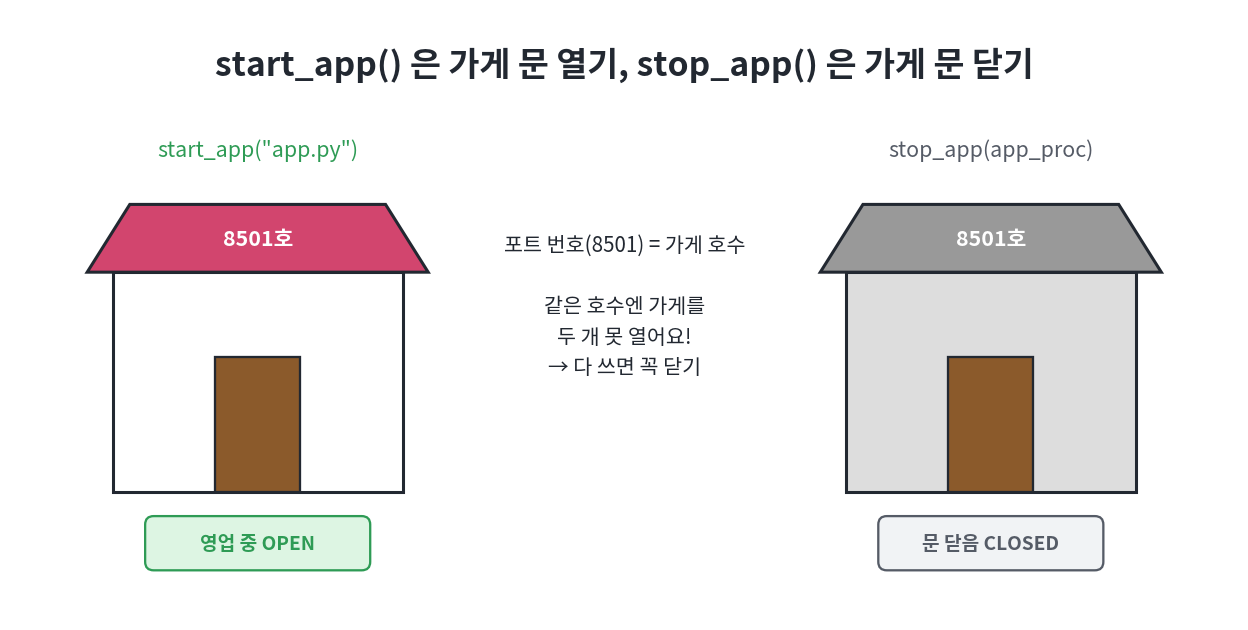

In [7]:
# ============================================================
# [6] 노트북에서 Streamlit 앱 '가게 문 열기 / 닫기' 도우미 함수
# ============================================================
# Streamlit 앱은 노트북 칸 안에서 돌아가지 않아요. 따로 '가게(웹 서버)'를 열어야 해요.
#   원래는 터미널에서:  streamlit run app.py
# subprocess = 파이썬이 '다른 프로그램'을 대신 켜 주는 도구. 이걸로 가게를 뒤에서 열어요.
import subprocess, time, urllib.request   # urllib.request = 인터넷 주소에 노크해 보는 도구

def start_app(script, port=8501, wait=60):
    """script(앱 파일)로 가게를 열고, 문이 열릴 때까지 기다렸다가 가게(프로세스)를 돌려줘요.
    port = 가게 호수. 같은 호수에는 가게를 두 개 열 수 없어요."""
    cmd = [sys.executable, "-m", "streamlit", "run", script,   # "파이썬아, streamlit 으로 이 파일 실행해 줘"
           "--server.port", str(port),                          # 몇 호에 열지
           "--server.headless", "true"]   # headless = 이메일 질문·브라우저 자동 열기 같은 건 건너뛰기
    proc = subprocess.Popen(cmd, cwd=WORK_DIR,                  # 우리 폴더에서 가게 열기 (뒤에서 몰래)
                            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)   # 가게 안 소음(로그)은 안 보이게
    url = f"http://localhost:{port}"                            # localhost = '내 컴퓨터' 라는 뜻
    for _ in range(wait):                 # 1초마다 "문 열었어요?" 하고 노크 (/_stcore/health 가 "ok" 면 열린 것)
        try:
            if urllib.request.urlopen(url + "/_stcore/health", timeout=1).read() == b"ok":
                print(f"실행 중: {url}  <- 브라우저에서 열어 보세요")
                return proc
        except Exception:                 # 아직 안 열렸으면 오류가 나요 -> 1초 쉬고 다시 노크
            time.sleep(1)
    print("서버가 시작되지 않았습니다. 터미널에서 직접 실행해 오류 메시지를 확인하세요:")
    print("  ", " ".join(cmd))
    return proc


def stop_app(proc):
    """start_app 으로 연 가게 문 닫기. 안 닫으면 그 호수(포트)를 계속 차지하고 있어요."""
    if proc and proc.poll() is None:      # poll() 이 None = "아직 영업 중"
        proc.terminate()                  # 가게 문 닫아 주세요!
        proc.wait(timeout=10)             # 다 닫힐 때까지 최대 10초 기다리기
    print("종료했습니다.")

### 미니 앱 체험하기
아래 칸을 실행하고 나오는 주소(`http://localhost:8501`)를 브라우저에서 열어 보세요. 그리고 이렇게 관찰해요.
1. **+1 누르기**를 여러 번 → "실행된 시각"이 누를 때마다 바뀌나요? (= 처음부터 다시 읽기) 칠판 숫자와 사물함 숫자는 어떻게 달라요?
2. 처음 열 때 3초 걸린 "모델 로딩 시각"이 그다음에도 그대로인가요? (= 냉장고)
3. 이름 칸에 글자를 칠 때는 아무 일도 없다가, **제출**을 눌러야 반응하나요? (= 편지 봉투)

In [8]:
# hello_app.py 가게 열기 (8501호)
# -> 브라우저에서 버튼·제출을 눌러 보며 시각과 숫자가 어떻게 바뀌는지 관찰해 보세요
hello_proc = start_app("hello_app.py", port=8501)

실행 중: http://localhost:8501  <- 브라우저에서 열어 보세요


In [9]:
# 관찰이 끝나면 가게 문 닫기 (안 닫으면 다음 앱을 8501호에 못 열어요)
stop_app(hello_proc)

종료했습니다.


<div style="border-left:5px solid #2f6fd1;background:#eef5ff;padding:10px 14px">

**도움말 **

- **"8501호(포트)가 이미 쓰는 중"** 이라고 나오면 → 전에 연 가게를 `stop_app` 으로 안 닫았거나 터미널에서 연 가게가 남아 있어요. `port=8503` 처럼 다른 호수로 바꿔 보세요.
- **Windows 방화벽 창**이 뜨면 '허용'을 눌러요. (내 컴퓨터 안에서만 쓰니까 '개인 네트워크'만 허용해도 충분해요.)
</div>

---
# Part 3. FashionRAG 웹 앱 만들기

### 화면은 이렇게 생겼어요
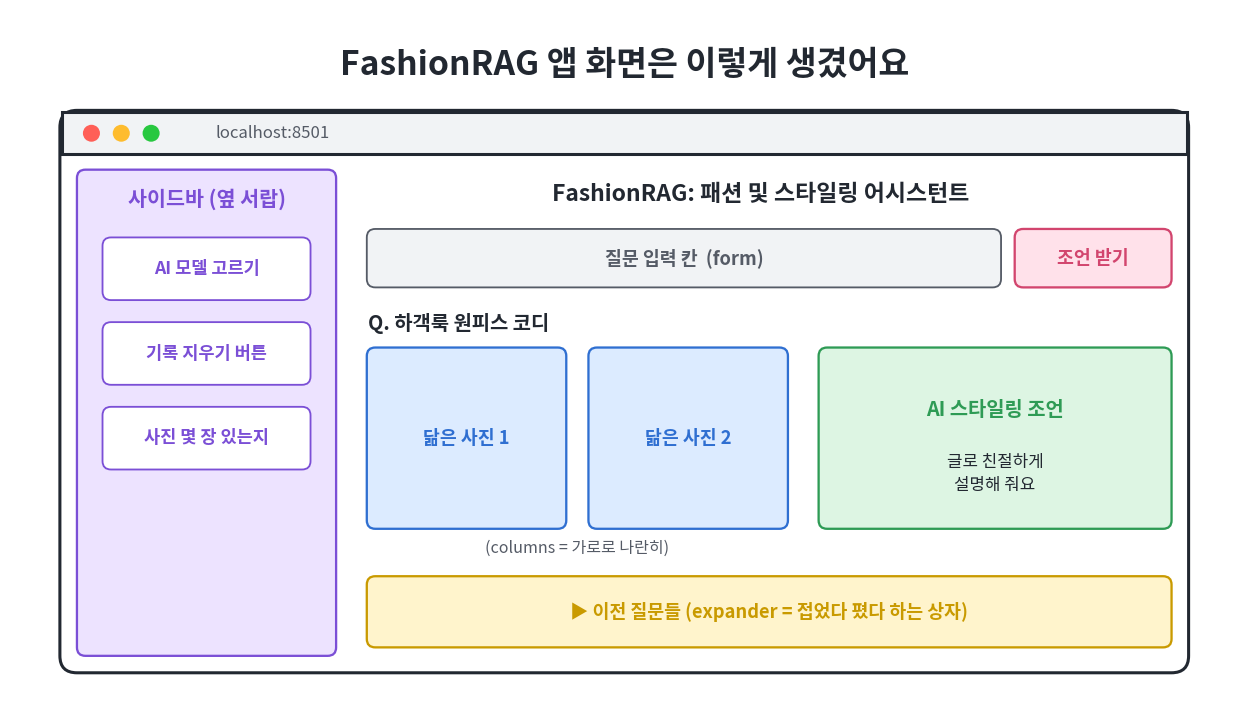

### 다시 읽을 때마다 위에서부터 이 순서로 실행돼요
| 순서 | 코드 | 쉽게 말하면 |
|---|---|---|
| 1 | `st.set_page_config` | 탭 이름 정하기 (꼭 제일 먼저) |
| 2 | `check_api_key()` 실패하면 `st.error` + `st.stop()` | 열쇠가 없으면 안내만 하고 멈추기 |
| 3 | 옆 서랍 `selectbox` | 어떤 AI 모델을 쓸지 고르기 |
| 4 | `load_collection()` | 냉장고(`@st.cache_resource`)에서 CLIP·창고 꺼내기 (처음만 만들기) |
| 5 | 사물함에 `data_ready` 가 없으면 준비 + 진행 막대 | 사물함, 진행 상자(`st.status`), 연락 함수 |
| 6 | `load_chains(vision_model)` | 고른 모델별로 냉장고 칸이 따로 있어요 |
| 7 | `st.form` → 제출하면 `core.ask()` | 편지 봉투, 문제 생기면 `try/except` 로 안내 |
| 8 | 결과를 `history` 맨 앞에 넣고 보여 주기 | 사물함 기록장, 가로 나란히(`st.columns`), 접는 상자(`st.expander`) |

In [10]:
%%writefile app.py
# ============================================================
# app.py - FashionRAG 의 '홀 직원' (손님에게 보여 주는 화면 담당)
# 켜는 방법:  streamlit run app.py
# ============================================================
import streamlit as st              # 화면 만드는 도구
import fashion_rag_core as core     # 진짜 요리는 '주방' 파일에 부탁해요

# set_page_config 는 꼭 '제일 먼저' 써야 하는 st 명령이에요.
# (브라우저 탭에 보일 이름 + 화면을 넓게 쓰기)
st.set_page_config(page_title="FashionRAG", layout="wide")
st.title("FashionRAG: 패션 및 스타일링 어시스턴트")


# ------------------------------------------------------------
# 냉장고(캐시): Streamlit 은 버튼을 누를 때마다 이 파일을 1줄부터 다시 읽어요.
#   무거운 것을 매번 새로 만들면 너무 느리니까, 한 번 만들어 냉장고에 넣어 두고 꺼내 써요.
# [원래 코드의 문제] 질문할 때마다 600MB 짜리 CLIP 을 다시 불러와서 엄청 느렸어요.
# ------------------------------------------------------------
@st.cache_resource(show_spinner="CLIP 모델과 벡터 DB를 불러오는 중...")   # 처음 만들 때 이 글자를 보여 줘요
def load_collection():
    return core.get_collection()


@st.cache_resource(show_spinner=False)
def load_chains(vision_model):
    # 냉장고 칸은 '재료(vision_model)'별로 따로 있어요.
    # 다른 모델을 고르면 새로 만들고, 전에 골랐던 모델이면 냉장고에서 꺼내요.
    return core.build_chains(vision_model=vision_model)


# ------------------------------------------------------------
# 0) 비밀 열쇠 확인 - 없으면 무서운 빨간 글씨 대신 '안내 문장'만 보여 주고 멈추기
# ------------------------------------------------------------
try:                               # try = "한번 해 보고"
    core.check_api_key()
except ValueError as e:            # except = "문제가 생기면 여기로"
    st.error(str(e))               # 빨간 안내 상자에 이유 보여 주기
    st.stop()                      # 여기서 멈춰! 아래 줄은 실행하지 않아요


# ------------------------------------------------------------
# 1) 옆 서랍(사이드바): 설정
# ------------------------------------------------------------
with st.sidebar:                   # 이 안에 쓴 것은 화면 왼쪽 서랍에 들어가요
    st.header("설정")
    vision_model = st.selectbox("비전 모델", ["gpt-4o-mini", "gpt-4o"],     # 골라 고르기 상자
                                help="gpt-4o 는 더 정확하지만 비용이 더 듭니다.")
    if st.button("대화 기록 지우기"):
        st.session_state.history = []                # 사물함 속 기록을 빈 목록으로 비우기


# ------------------------------------------------------------
# 2) 재료 준비 + 창고 정리 (손님 한 명당 처음 한 번만 확인)
#    session_state(사물함) 에 "준비 끝!" 표시를 해 두면 다시 실행돼도 또 하지 않아요
# ------------------------------------------------------------
collection = load_collection()                       # 냉장고에서 사진 창고 꺼내기

if not st.session_state.get("data_ready"):          # 사물함에 "준비 끝" 표시가 없으면
    with st.status("데이터 준비 상태 확인 중...", expanded=True) as status:   # 진행 상황 상자
        bar = st.progress(0.0, text="이미지 확인 중")                          # 진행 막대 (0%)
        # 심부름꾼에게 '진행 막대 채우기 함수'를 연락 방법(콜백)으로 맡겨요
        # lambda d, t: ... = 이름 없는 짧은 함수. d = 한 개수, t = 전체 개수
        core.ensure_dataset(progress=lambda d, t: bar.progress(d / t, text=f"이미지 저장 {d}/{t}"))
        core.index_images(collection, progress=lambda d, t: bar.progress(d / t, text=f"임베딩 색인 {d}/{t}"))
        bar.progress(1.0, text="완료")                                          # 막대 100%
        status.update(label=f"준비 완료 - DB 이미지 {collection.count()}장", state="complete", expanded=False)
    st.session_state.data_ready = True               # 사물함에 "준비 끝!" 표시

st.sidebar.caption(f"DB 이미지 수: {collection.count()}장")   # 서랍에 작은 글씨로 사진 수 보여 주기
chains = load_chains(vision_model)                   # 고른 모델의 AI 줄을 냉장고에서 꺼내기

if "history" not in st.session_state:
    st.session_state.history = []        # 사물함에 '질문 기록장' 만들기 (질문·사진·답이 하나씩 쌓여요)


# ------------------------------------------------------------
# 3) 질문 받기 - 편지 봉투(form): '조언 받기' 버튼을 눌렀을 때만 처리해요
# [원래 코드의 문제] 입력 칸에 글자가 남아 있어서, 다른 버튼만 눌러도 AI 를 또 불렀어요(돈이 들어요!)
# ------------------------------------------------------------
st.header("스타일링 조언을 받아보세요")
with st.form("ask_form", clear_on_submit=True):     # clear_on_submit = 제출하면 입력 칸을 깨끗이 비우기
    query_ko = st.text_input("스타일링에 대한 질문을 입력하세요:",
                             placeholder="예) 하객룩으로 어울리는 원피스 코디")   # 흐린 예시 글자
    submitted = st.form_submit_button("조언 받기")

if submitted and query_ko.strip():                   # 제출했고, 빈칸이 아닐 때만 (strip = 앞뒤 빈칸 지우기)
    try:
        with st.spinner("번역 -> 이미지 검색 -> 스타일링 조언 생성 중..."):   # 빙글빙글 기다림 표시
            result = core.ask(collection, chains, query_ko.strip())       # 주방에 요리 부탁!
        st.session_state.history.insert(0, result)   # 새 결과를 기록장 '맨 앞'에 끼워 넣기
    except Exception as e:
        # 인터넷이 끊기거나 AI 쪽에 문제가 생겨도 앱 전체가 깨지지 않게, 안내 문장만 보여 줘요
        st.error(f"처리 중 오류가 발생했습니다: {e}")


# ------------------------------------------------------------
# 4) 결과 보여 주기 - 가장 최근 것은 크게, 예전 것은 접어서
# ------------------------------------------------------------
def render(result):
    """결과 하나를 화면에 그려 주는 함수 (질문 영어 번역 → 사진들 → AI 조언)"""
    st.caption(f"번역된 질문: {result['query_en']}")
    cols = st.columns(len(result["uris"]))            # 사진 수만큼 화면을 가로로 나란히 나누기
    for col, pid, uri, dist in zip(cols, result["ids"], result["uris"], result["distances"]):
        # st.image 는 사진 파일 주소만 줘도 바로 보여 줘요 (글자로 바꿀 필요 없어요)
        col.image(uri, caption=f"{pid} (거리 {dist:.3f})", width=300)
    st.markdown(result["answer_ko"])                  # AI 조언을 꾸민 글(마크다운)로 보여 주기


if st.session_state.history:                         # 기록장에 뭔가 있으면
    latest, *older = st.session_state.history         # 맨 앞 1개 = latest(최신), 나머지 = older(예전)
    st.subheader(f"Q. {latest['query_ko']}")
    render(latest)
    if older:
        st.divider()                                  # 가로줄 긋기
        st.subheader("이전 질문")
        for past in older:
            with st.expander(f"Q. {past['query_ko']}"):   # 접었다 폈다 하는 상자
                render(past)
else:
    st.info("질문을 입력하면 비슷한 패션 사진 2장과 함께 스타일링 조언을 드립니다.")   # 아직 질문이 없을 때 파란 안내

Writing app.py


### 앱 켜 보기
아래 칸을 실행하고 `http://localhost:8501` 을 열어요. 이런 질문을 해 보세요: `하객룩으로 어울리는 원피스`, `캐주얼한 데님 재킷 코디`, `여름 휴가지에서 입을 린넨 셔츠`

**터미널(PowerShell)에서 직접 켜는 방법** — 오류가 났을 때 무슨 말인지 자세히 보고 싶으면 이렇게 해요.
```powershell
cd C:\workspaces\fashionRAG-assistant      # 노트북과 app.py 가 있는 폴더로 이동
.\.venv\Scripts\Activate.ps1               # 가상환경(우리 도구 상자) 켜기
streamlit run app.py                          # 앱 켜기 (브라우저가 저절로 열려요, 끌 때는 Ctrl + C)
```

In [ ]:
# FashionRAG 앱 가게 열기 -> 브라우저에서 질문해 보세요
app_proc = start_app("app.py", port=8501)

In [ ]:
# 다 썼으면 가게 문 닫기
stop_app(app_proc)

<div style="border-left:5px solid #2f6fd1;background:#eef5ff;padding:10px 14px">

**도움말 - 막히면 읽어 보세요**

- 앱에서 오류가 나면, 노트북 방식(`start_app`)은 오류 메시지를 숨겨요. 위의 **터미널 방법**으로 켜서 메시지를 읽어 보세요.
- `app.py` 를 고치고 저장하면 브라우저 오른쪽 위에 **Rerun / Always rerun** 이 나타나요. 가게를 다시 열 필요가 없어요!
- 단, 주방 파일 `fashion_rag_core.py` 를 고쳤다면 가게를 닫았다(`stop_app`) 다시 여는 게 안전해요.

</div>

---
# Part 4. 직접 해 보기 — CLIP 사진 검색기 앱

OpenAI 를 쓰지 않고 **CLIP + Chroma 만으로** 움직이는 사진 검색 앱을 완성해요. (AI 사용료가 0원!)

| 실습 | 할 일 | 쓰는 개념 |
|---|---|---|
| 1 | 옆 서랍에 '찾을 사진 수' 미끄럼 막대 만들기 (1~6, 처음엔 3) | `st.sidebar`, `st.slider`, 다시 읽기 |
| 2 | 검색 기록장을 사물함(`session_state`)에 만들기 | `st.session_state` |
| 3 | 사진 아래에 이름표와 거리(소수점 3자리) 쓰기 | `st.image(caption=...)`, f-string |

아래 칸에서 `# TODO` 라고 적힌 3곳을 채우고 `%%writefile` 칸을 실행한 다음, 실행 칸으로 확인해요.

In [11]:
%%writefile app_practice.py
# ============================================================
# app_practice.py - [실습] OpenAI 없이 CLIP 만으로 사진을 찾는 앱 (돈이 안 들어요!)
# ============================================================
import streamlit as st
import fashion_rag_core as core

st.set_page_config(page_title="FashionRAG 실습", layout="wide")   # 꼭 제일 먼저!
st.title("실습: 패션 이미지 검색기")


@st.cache_resource(show_spinner="CLIP 모델 로딩 중...")   # 무거운 CLIP 은 냉장고에 한 번만
def load_collection():
    return core.get_collection()

collection = load_collection()

# [실습 1] 옆 서랍에 미끄럼 막대(슬라이더) 만들기
#   막대를 움직이면 → 파일이 1줄부터 다시 실행되고 → n 에 새 숫자가 들어가요
with st.sidebar:
    # TODO 1: st.slider 로 "검색할 이미지 수" 막대를 만드세요. (가장 작게 1, 가장 크게 6, 처음 값 3)
    #   힌트: n = st.slider("이름", min_value=?, max_value=?, value=?)
    n = st.slider("검색할 이미지 수", min_value=1, max_value=6, value=3)
    st.caption(f"DB 이미지 수: {collection.count()}장")

# [실습 2] 사물함(session_state)에 '검색 기록장' 만들기 - 다시 실행돼도 기록이 남아요
if "searches" not in st.session_state:             # 처음 한 번만 빈 기록장을 만들어요
    # TODO 2: 사물함의 searches 에 빈 목록 [] 을 넣으세요.
    #   힌트: st.session_state.이름 = 값
    st.session_state.searches = []

query = st.text_input("영어 검색어를 입력하세요 (예: a red dress)")
if query:                                           # 뭔가 입력했다면
    results = core.query_db(collection, query, n_results=n)   # n 장 찾기
    cols = st.columns(n)                            # n 칸으로 가로 나누기
    for col, pid, uri, dist in zip(cols, results["ids"][0], results["uris"][0], results["distances"][0]):
        # [실습 3] TODO 3: 사진 아래 글(caption)에 이름표 pid 와 거리 dist 를 같이 보여 주세요.
        #   거리는 소수점 아래 3자리까지만! (예: image_0012 (거리 0.812))
        #   힌트: f-string 안에서 {dist:.3f} 라고 쓰면 3자리까지만 보여 줘요
        col.image(uri, caption=f"{pid} (거리 {dist:.3f})", width=200)
    if query not in st.session_state.searches:      # 같은 검색어는 두 번 적지 않기
        st.session_state.searches.append(query)     # 기록장 맨 뒤에 적기

st.subheader("검색 기록")
for q in st.session_state.searches:
    st.write("-", q)

Writing app_practice.py


In [12]:
# 실습 앱 가게 열기 (FashionRAG 앱과 겹치지 않게 8502호에!)
practice_proc = start_app("app_practice.py", port=8502)

실행 중: http://localhost:8502  <- 브라우저에서 열어 보세요


In [ ]:
# 실습이 끝나면 가게 문 닫기
stop_app(practice_proc)

종료했습니다.


<div style="border-left:5px solid #2f6fd1;background:#eef5ff;padding:10px 14px">

**도움말 - 막히면 읽어 보세요**

- TODO 를 안 채우고 실행하면 브라우저에 빨간 오류가 떠요. 놀라지 말고, 오류 화면에서 **몇 번째 줄이 문제인지** 찾아보세요.
- 실습 2 확인 방법: 검색어를 여러 번 바꿔 입력해 보세요. 아래 '검색 기록'이 차곡차곡 쌓이면 성공!
- 도전 과제: 미끄럼 막대 대신 `st.number_input`(숫자 칸) 써 보기 / 검색 기록을 누르면 다시 검색되도록 `st.button` 으로 바꿔 보기

</div>

---
# 확인 퀴즈
스스로 답을 적어 보고, 친구와 비교해 보세요. (힌트는 그림 속에 다 있어요!)

| # | 질문 | 내 답 |
|---|---|---|
| 1 | Streamlit 에서 버튼을 누르면 파일은 어떻게 실행될까요? | 파일 전체가 첫 줄부터 끝까지 다시 실행된다. |
| 2 | 다시 실행돼도 값을 남겨 두려면 무엇을 써야 할까요? (힌트: 사물함) | st.session_state |
| 3 | `@st.cache_resource` 를 왜 쓸까요? (힌트: 냉장고) | 모델과 DB연결처럼 무거운 자원을 한 번 만들어두고 재사용하기 위해서 |
| 4 | `st.form` 을 쓰면 무엇이 좋을까요? (힌트: 편지 봉투) | AI 사용료 절약 |
| 5 | 처음 만든 앱은 왜 첫 실행에서 멈췄을까요? (`fashion_rag_core.py` 의 `index_images` 설명을 읽어 보세요) | |
| 6 | Streamlit 앱 코드는 왜 꼭 `.py` 파일이어야 할까요? | |
| 7 | 주방(`fashion_rag_core.py`)과 홀(`app.py`)을 나누면 좋은 점 두 가지는? | 화면을 바꿔도 기존 로직을 재사용 할 수 있다. |

---
# 오늘 배운 것 정리

| 배운 것 | 한 줄 요약 | 비유 |
|---|---|---|
| 다시 읽기(rerun) | 위젯을 건드리면 파일 전체를 다시 실행 | 요리책을 1쪽부터 다시 읽기 |
| `st.session_state` | 다시 실행돼도 남는 손님별 저장소 (대화 기록, 준비 끝 표시) | 내 사물함 |
| `@st.cache_resource` | 모델·DB 연결은 앱 전체에서 한 번만 | 모두 같이 쓰는 냉장고 |
| `st.form` | 제출할 때만 처리 → AI 사용료 절약 | 편지 봉투와 우체통 |
| 주방/홀 나누기 | `fashion_rag_core.py` 를 노트북과 앱이 함께 사용 | 주방과 홀 직원 |
| 켜기 | `streamlit run app.py` (노트북에서는 `start_app()`) | 가게 문 열기 |

### 더 해 보고 싶다면
- `st.chat_input` + `st.chat_message` 로 **카톡 같은 채팅 화면** 만들기
- `st.file_uploader` 로 **내 옷 사진을 올려서** 비슷한 스타일 찾기 (사진 → 사진, `query_uris`)
- **Streamlit Community Cloud** 에 올려서 친구에게 링크로 보여 주기 (비밀 열쇠는 Secrets 기능에 숨겨 두기)